In [10]:
# !pip install wfdb -q
# !pip install ecg-plot -q
# !pip install neurokit2 -q
# !pip install pydicom 

import wfdb
import numpy as np
import matplotlib.pyplot as plt
import neurokit2 as nk
import pandas as pd
from matplotlib.ticker import AutoMinorLocator, FuncFormatter
from scipy.signal import find_peaks

# --- Provided plot_ecg_with_grid function  ---
def plot_ecg_with_grid(time, signal, title, ax, sampling_rate, show_grid=True, style='color'):
    """Plots ECG signal with a grid resembling ECG paper."""
    if (style == 'bw'):
        color_major = (0.4, 0.4, 0.4)
        color_minor = (0.75, 0.75, 0.75)
        color_line  = (0, 0, 0)
    else:
        color_major = (1, 0, 0)
        color_minor = (1, 0.7, 0.7)
        color_line  = (0, 0, 0.7)

    ax.plot(time, signal, color=color_line, linewidth=1.0)
    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Time (s)', fontsize=12)
    ax.set_ylabel('Amplitude (mV)', fontsize=12)

    if(show_grid):
        dt = 1.0 / sampling_rate
        x_min_data, x_max_data = np.min(time), np.max(time)
        y_min_data, y_max_data = np.min(signal), np.max(signal)

        y_padding = 0.5
        ax.set_xlim(x_min_data, x_max_data)
        ax.set_ylim(y_min_data - y_padding, y_max_data + y_padding)

        x_min_plot, x_max_plot = ax.get_xlim()
        y_min_plot, y_max_plot = ax.get_ylim()

        major_xticks = np.arange(np.floor(x_min_plot / 0.2) * 0.2, np.ceil(x_max_plot / 0.2) * 0.2 + 0.01, 0.2)
        major_yticks = np.arange(np.floor(y_min_plot / 0.5) * 0.5, np.ceil(y_max_plot / 0.5) * 0.5 + 0.01, 0.5)

        ax.set_xticks(major_xticks)
        ax.set_yticks(major_yticks)

        minor_xticks = np.arange(np.floor(x_min_plot / 0.04) * 0.04, np.ceil(x_max_plot / 0.04) * 0.04 + 0.01, 0.04)
        minor_yticks = np.arange(np.floor(y_min_plot / 0.1) * 0.1, np.ceil(y_max_plot / 0.1) * 0.1 + 0.01, 0.1)

        ax.set_xticks(minor_xticks, minor=True)
        ax.set_yticks(minor_yticks, minor=True)

        ax.grid(which='major', linestyle='-', linewidth=0.5 * 1, color=color_major, alpha=0.7)
        ax.grid(which='minor', linestyle='-', linewidth=0.25 * 1, color=color_minor, alpha=0.5)

    ax.tick_params(axis='both', which='major', labelsize=10)

# --- Helper function to load WFDB data ---
def load_wfdb_signal(filename, lead_index, db_dir=None):
    """Loads a specific lead from a WFDB record."""
    try:
        record = wfdb.rdrecord(filename, pn_dir=db_dir)
        ecg_signal = record.p_signal[:, lead_index]
        sampling_rate = record.fs
        sig_name = record.sig_name[lead_index]
        if record.units[lead_index].lower() == 'uv':
            ecg_signal = ecg_signal / 1000.0
            print(f"Signal for {sig_name} converted from uV to mV.")
        elif record.units[lead_index].lower() != 'mv':
            print(f"Warning: Signal unit for {sig_name} is {record.units[lead_index]}, not mV.")
        print(f"Loaded {filename}, Lead: {sig_name}, Sampling Rate: {sampling_rate} Hz, Length: {len(ecg_signal)} samples")
        return ecg_signal, sampling_rate, sig_name
    except Exception as e:
        print(f"Error loading WFDB record {filename} (pn_dir='{db_dir}'): {e}")
        return None, None, None

def load_wfdb_signals(filename, leads="all", db_dir=None, allow_missing=True):
    record = wfdb.rdrecord(filename, pn_dir=db_dir)
    fs, names = record.fs, record.sig_name
    units = [u.lower() for u in record.units]

    # helper – 不区分大小写
    def _name2idx(nm):
        for i, n in enumerate(names):
            if n.lower() == nm.lower():
                return i
        return None

    if leads == "all":
        idx_keep = range(len(names))
    else:
        if not isinstance(leads, (list, tuple)):
            leads = [leads]
        idx_keep = []
        for item in leads:
            if isinstance(item, int):
                if item < len(names):
                    idx_keep.append(item)
                elif not allow_missing:
                    raise ValueError(f"Lead index {item} out of range")
            else:  # str
                j = _name2idx(item)
                if j is not None:
                    idx_keep.append(j)
                elif allow_missing:
                    print(f"[load] lead '{item}' not found – skipped")
                else:
                    raise ValueError(f"Lead '{item}' not in record")

    out = {}
    for j in idx_keep:
        sig = record.p_signal[:, j]
        if units[j] == "uv":
            sig = sig / 1000.0
        out[names[j]] = (sig, fs)
    return out

# ──────────────────────────────────────────────────────────────
# Tools：uper/lower case delineation KEY
# ──────────────────────────────────────────────────────────────
def _waves_get(waves, key_name):
    if waves is None:
        return []
    key_name_l = key_name.lower()
    for k, v in waves.items():
        if k.lower() == key_name_l:
            return v
    return []

def print_observation_1davb(
    pr_intervals,
    used_delineation_method,
    ecg_title,
    lead_name,
    sampling_rate # 保留以备将来可能的使用，例如计算小格数
):
    print(f"\nClinical Observation for {ecg_title} ({lead_name}):")

    if pr_intervals is None or len(pr_intervals) == 0:
        delineation_status = used_delineation_method if used_delineation_method else "Failed"
        print(f"- Automatic delineation (method: {delineation_status}) could not reliably compute PR intervals.")
        print("- Key feature of 1st Degree AV Block: Consistently prolonged PR interval (> 0.20 seconds).")
        print("- Each P-wave should be followed by a QRS complex.")
        print("- Please visually inspect the ECG trace for these features.")
        return

    mean_pr = np.mean(pr_intervals)
    min_pr = np.min(pr_intervals)
    max_pr = np.max(pr_intervals)
    count_total = len(pr_intervals)
    count_prolonged = np.sum(pr_intervals > 0.20)

    print(f"- PR interval is prolonged if > 0.20 seconds (5 small squares at 25mm/s).")
    print(f"- Calculated PR intervals: Mean={mean_pr:.3f}s, Min={min_pr:.3f}s, Max={max_pr:.3f}s.")

    if count_total > 0:
        percentage_prolonged = (count_prolonged / count_total) * 100
        print(f"- {count_prolonged} out of {count_total} ({percentage_prolonged:.1f}%) calculated PR intervals are > 0.20s.")
    else:
        print("- No PR intervals were successfully calculated to assess prolongation.")

    if count_prolonged == count_total and count_total > 0:
        print(f"  - The histogram for this segment shows PR intervals consistently above the 0.20s threshold, characteristic of 1st Degree AV Block.")
    elif count_prolonged > 0 and count_total > 0:
        print(f"  - The histogram shows some PR intervals above the 0.20s threshold, suggesting potential 1st Degree AV Block or intermittent prolongation.")
    elif count_total > 0:
         print(f"  - The histogram shows PR intervals generally within or below the 0.20s normal limit for this segment.")
    print(f"- In 1st Degree AV Block, each P-wave is typically followed by a QRS complex, and the rhythm is often regular.")



--- Processing AFIB: 16731_hr ---
Loaded 16731_hr, Lead: II, Sampling Rate: 500 Hz, Length: 5000 samples


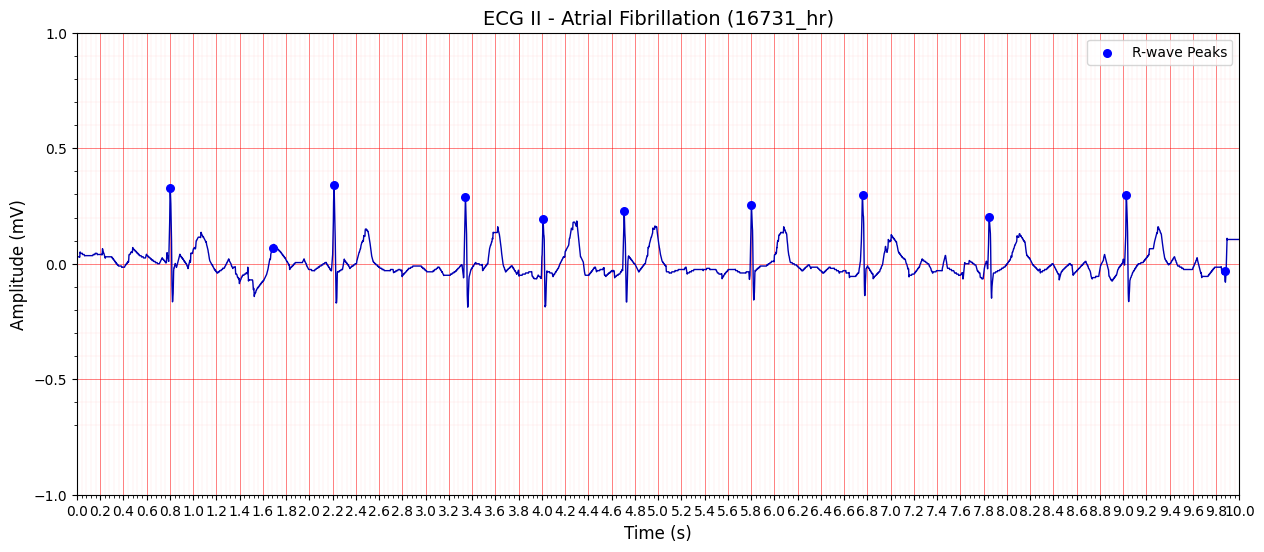

RR Stats for Atrial Fibrillation (16731_hr): Min=0.526, Max=1.180, Mean=0.907, StdDev=0.211, Count=10


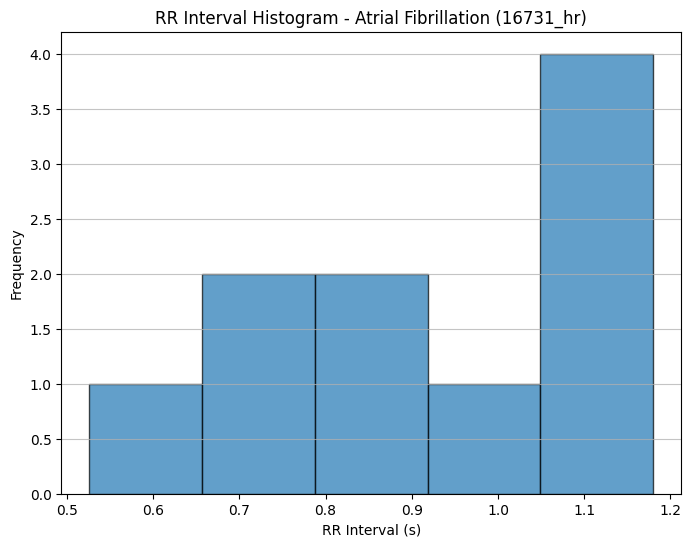

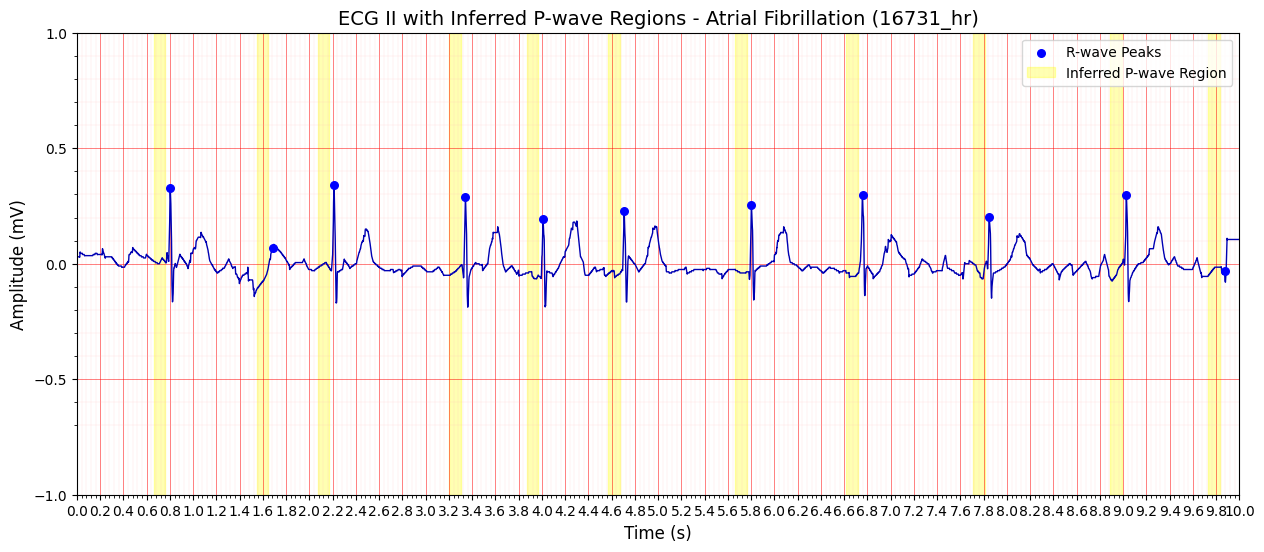


Observation for Atrial Fibrillation (16731_hr) (II):
- P-waves typically absent/fibrillatory.
- Yellow boxes: Inferred P-wave regions.
- RR histogram shows 'irregularly irregular' rhythm.


In [11]:
# --- Visualization function for AFIB (Real Data) - Includes plt.close() ---
def visualize_afib_real(ecg_signal, sampling_rate, ecg_title="AFIB", lead_name="Lead"):
    if ecg_signal is None: return
    time_axis = np.linspace(0, len(ecg_signal) / sampling_rate, len(ecg_signal), endpoint=False)
    try:
        _, r_peaks = nk.ecg_peaks(ecg_signal, sampling_rate=sampling_rate)
        r_peak_indices = r_peaks['ECG_R_Peaks']
    except Exception as e:
        print(f"R-peak detection failed for {ecg_title}: {e}")
        fig_ecg_fail, ax_ecg_fail = plt.subplots(figsize=(15, 4))
        plot_ecg_with_grid(time_axis, ecg_signal, f'ECG {lead_name} - {ecg_title} (R-peak detection failed)', ax_ecg_fail, sampling_rate)
        plt.show()
        plt.close(fig_ecg_fail)
        return

    if len(r_peak_indices) < 2:
        print(f"Not enough R-peaks found in {ecg_title} to analyze RR intervals or P-waves.")
        fig_ecg_few, ax_ecg_few = plt.subplots(figsize=(15, 4))
        plot_ecg_with_grid(time_axis, ecg_signal, f'ECG {lead_name} - {ecg_title} (Few R-peaks)', ax_ecg_few, sampling_rate)
        if len(r_peak_indices) > 0 : ax_ecg_few.scatter(time_axis[r_peak_indices], ecg_signal[r_peak_indices], color='blue', marker='o', s=30, label='R-wave Peaks', zorder=5); ax_ecg_few.legend()
        plt.show()
        plt.close(fig_ecg_few)
        return

    fig_ecg, ax_ecg = plt.subplots(figsize=(15, 6))
    plot_ecg_with_grid(time_axis, ecg_signal, f'ECG {lead_name} - {ecg_title}', ax_ecg, sampling_rate)
    ax_ecg.scatter(time_axis[r_peak_indices], ecg_signal[r_peak_indices], color='blue', marker='o', s=30, label='R-wave Peaks', zorder=5)
    ax_ecg.legend()
    plt.show()
    plt.close(fig_ecg)

    rr_intervals_sec = np.diff(r_peak_indices) / sampling_rate
    fig_hist, ax_hist = plt.subplots(figsize=(8, 6))
    try:
        if len(rr_intervals_sec) > 0:
            n, bins, patches = ax_hist.hist(rr_intervals_sec, bins='auto', edgecolor='black', alpha=0.7)
            ax_hist.set_title(f'RR Interval Histogram - {ecg_title}')
            ax_hist.set_xlabel('RR Interval (s)'); ax_hist.set_ylabel('Frequency'); ax_hist.grid(axis='y', alpha=0.75)
            print(f"RR Stats for {ecg_title}: Min={np.min(rr_intervals_sec):.3f}, Max={np.max(rr_intervals_sec):.3f}, Mean={np.mean(rr_intervals_sec):.3f}, StdDev={np.std(rr_intervals_sec):.3f}, Count={len(rr_intervals_sec)}")
        else: ax_hist.text(0.5, 0.5, "No RR intervals.", horizontalalignment='center'); ax_hist.set_title(f'RR Interval Histogram - {ecg_title}')
    except Exception as hist_e: print(f"Error histogram: {hist_e}"); ax_hist.text(0.5, 0.5, "Error histogram.", horizontalalignment='center')
    plt.show()
    plt.close(fig_hist)

    waves = None
    try:
        signals, waves_dict = nk.ecg_delineate(ecg_signal, rpeaks=r_peak_indices, sampling_rate=sampling_rate, method="dwt")
        waves = waves_dict
    except Exception as e: print(f"Delineation failed for {ecg_title}: {e}.")

    fig_pwave, ax_pwave = plt.subplots(figsize=(15, 6))
    plot_ecg_with_grid(time_axis, ecg_signal, f'ECG {lead_name} with Inferred P-wave Regions - {ecg_title}', ax_pwave, sampling_rate)
    ax_pwave.scatter(time_axis[r_peak_indices], ecg_signal[r_peak_indices], color='blue', marker='o', s=30, label='R-wave Peaks', zorder=5)
    p_wave_typical_duration_sec = 0.10
    qrs_onsets_from_delineation = []
    if waves is not None and 'ECG_QRS_Onsets' in waves: qrs_onsets_from_delineation = [int(q) for q in waves['ECG_QRS_Onsets'] if not np.isnan(q)]
    highlighted_p_region = False
    for i, r_peak_idx in enumerate(r_peak_indices):
        current_qrs_onset = None
        if qrs_onsets_from_delineation:
            potential_qrs_onsets = [q_onset for q_onset in qrs_onsets_from_delineation if q_onset < r_peak_idx and (r_peak_idx - q_onset) < (0.1 * sampling_rate)]
            if potential_qrs_onsets: current_qrs_onset = max(potential_qrs_onsets)
        qrs_onset_for_p_search = current_qrs_onset if current_qrs_onset is not None else (r_peak_idx - int(0.04 * sampling_rate))
        p_box_end_idx = qrs_onset_for_p_search
        p_box_start_idx = max(0, p_box_end_idx - int(p_wave_typical_duration_sec * sampling_rate))
        if p_box_start_idx < p_box_end_idx and p_box_end_idx < len(ecg_signal):
            label = 'Inferred P-wave Region' if not highlighted_p_region else ""; ax_pwave.axvspan(time_axis[p_box_start_idx], time_axis[p_box_end_idx], color='yellow', alpha=0.3, label=label); highlighted_p_region = True
    if highlighted_p_region: ax_pwave.legend(loc='upper right')
    plt.show()
    plt.close(fig_pwave)
    print(f"\nObservation for {ecg_title} ({lead_name}):\n- P-waves typically absent/fibrillatory.\n- Yellow boxes: Inferred P-wave regions.\n- RR histogram shows 'irregularly irregular' rhythm.")

# --- AFIB Visualization ---
afib_filename = "16731_hr"

afib_lead_index = 1  # Assuming Lead II
# For aftdb records, pn_dir is 'aftdb/'
# If your file is local, set afib_pn_dir = None
afib_pn_dir = None # Example: PhysioNet AF Termination Challenge DB

print(f"--- Processing AFIB: {afib_filename} ---")
ecg_afib, fs_afib, lead_name_afib = load_wfdb_signal(afib_filename, afib_lead_index, db_dir=afib_pn_dir)

if ecg_afib is not None and fs_afib is not None:
    # Optional: Truncate signal for faster processing/display if very long
    # max_display_sec = 20
    # if len(ecg_afib) > fs_afib * max_display_sec:
    #     ecg_afib = ecg_afib[:fs_afib * max_display_sec]
    #     print(f"Signal truncated to {max_display_sec}s for display.")

    visualize_afib_real(ecg_afib, fs_afib,
                        ecg_title=f"Atrial Fibrillation ({afib_filename})",
                        lead_name=lead_name_afib)
else:
    print(f"Could not load data for AFIB: {afib_filename}")





--- Processing LBBB: 03016_hr ---
Loaded 03016_hr, Lead: II, Sampling Rate: 500 Hz, Length: 5000 samples
Signal for Left Bundle Branch Block (03016_hr) cleaned using 'neurokit' method.
R-peaks detected on cleaned signal using 'neurokit' method. Found 19 R-peaks.


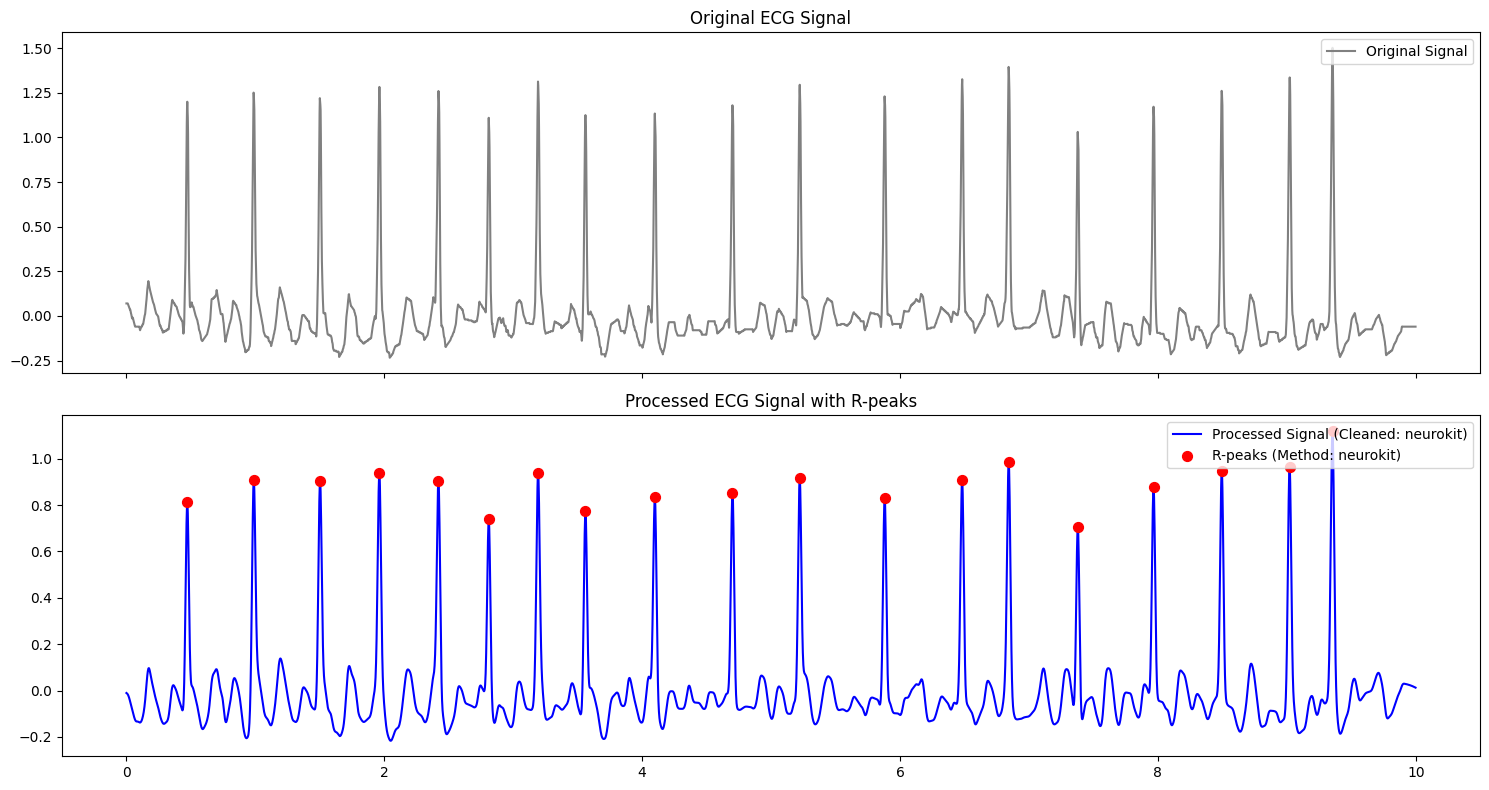


Attempting delineation with method: 'dwt'...
Delineation with 'dwt' did not yield valid QRS onsets/offsets.

Attempting delineation with method: 'cwt'...
Delineation with 'cwt' did not yield valid QRS onsets/offsets.

Attempting delineation with method: 'peak'...
Delineation with 'peak' did not yield valid QRS onsets/offsets.
All attempted delineation methods failed for Left Bundle Branch Block (03016_hr).
Attempting refined R-peak based QRS boundary estimation.
Refined Estimation QRS durations calculated.


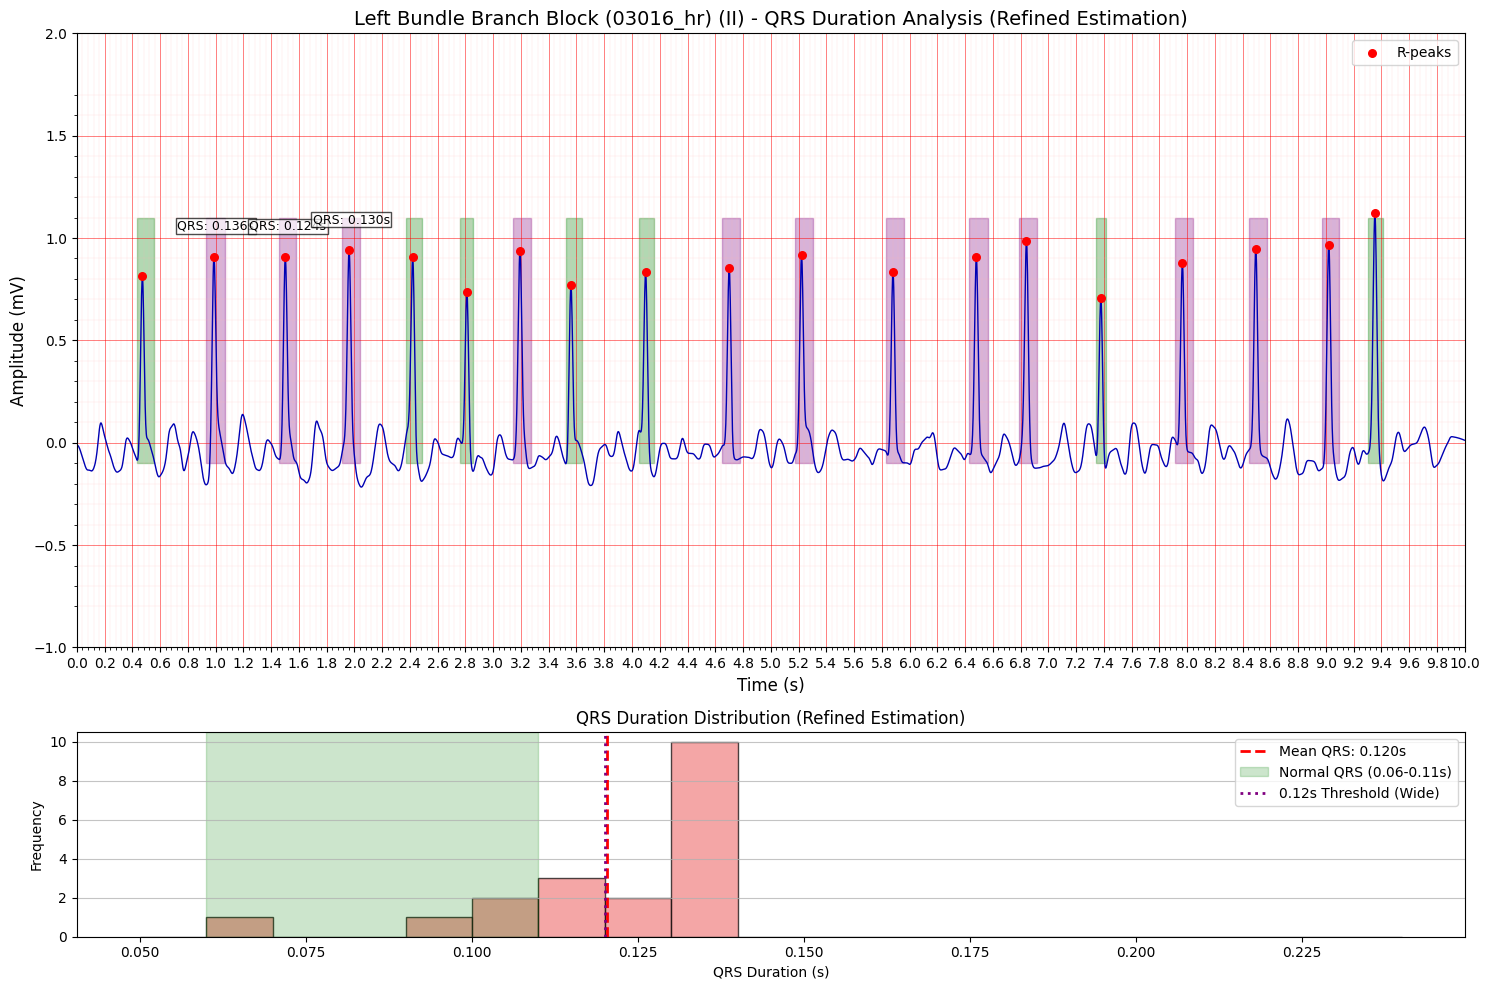


Clinical Observation for Left Bundle Branch Block (03016_hr) (II): QRS duration is considered prolonged if > 0.12 seconds (typically).
- QRS durations (Refined Estimation): Mean=0.120s, Min=0.068s, Max=0.136s.
- 12 out of 19 QRS durations (Refined Estimation) are > 0.12s.


In [3]:
# --- Visualization for Bundle Branch Blocks (Real Data) - WITH REFINED QRS ESTIMATION ATTEMPT ---
def visualize_bbb_real(ecg_signal, sampling_rate, abnormality_name, lead_name="Lead"):
    if ecg_signal is None: return

    # --- 1. Signal Cleaning ---
    cleaning_method_to_try = "neurokit"
    try:
        ecg_cleaned = nk.ecg_clean(ecg_signal, sampling_rate=sampling_rate, method=cleaning_method_to_try)
        print(f"Signal for {abnormality_name} cleaned using '{cleaning_method_to_try}' method.")
    except Exception as clean_e:
        print(f"Warning: Could not clean ECG signal for {abnormality_name} with method '{cleaning_method_to_try}': {clean_e}. Using raw signal.")
        ecg_cleaned = ecg_signal

    time_axis_orig = np.linspace(0, len(ecg_signal) / sampling_rate, len(ecg_signal), endpoint=False)
    time_axis_cleaned = np.linspace(0, len(ecg_cleaned) / sampling_rate, len(ecg_cleaned), endpoint=False)

    # --- 2. R-peak Detection (on cleaned signal) ---
    r_peak_indices_np = np.array([], dtype=int)
    rpeaks_for_delineation = None
    rpeak_method_to_try = "neurokit"
    try:
        _, rpeaks_detected_obj = nk.ecg_peaks(ecg_cleaned, sampling_rate=sampling_rate, method=rpeak_method_to_try)
        if 'ECG_R_Peaks' in rpeaks_detected_obj and rpeaks_detected_obj['ECG_R_Peaks'] is not None:
             r_peak_indices_np = rpeaks_detected_obj['ECG_R_Peaks']
             rpeaks_for_delineation = rpeaks_detected_obj
        print(f"R-peaks detected on cleaned signal using '{rpeak_method_to_try}' method. Found {r_peak_indices_np.size} R-peaks.")
    except Exception as rpeak_e:
        print(f"R-peak detection on cleaned signal failed with method '{rpeak_method_to_try}': {rpeak_e}")
        try:
            print("Attempting R-peak detection on raw signal as a fallback...")
            _, rpeaks_detected_obj = nk.ecg_peaks(ecg_signal, sampling_rate=sampling_rate, method=rpeak_method_to_try)
            if 'ECG_R_Peaks' in rpeaks_detected_obj and rpeaks_detected_obj['ECG_R_Peaks'] is not None:
                r_peak_indices_np = rpeaks_detected_obj['ECG_R_Peaks']
                rpeaks_for_delineation = rpeaks_detected_obj
            ecg_cleaned = ecg_signal
            time_axis_cleaned = time_axis_orig
            print(f"R-peaks detected on raw signal. Found {r_peak_indices_np.size} R-peaks. Proceeding with raw signal for delineation.")
        except Exception as rpeak_raw_e:
            print(f"R-peak detection on raw signal also failed: {rpeak_raw_e}")

    # --- Diagnostic Plot ---
    fig_diag, (ax_orig, ax_cleaned_diag) = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
    # ... (Diagnostic plot code from previous version - keeping it concise here) ...
    ax_orig.plot(time_axis_orig, ecg_signal, label="Original Signal", color='gray')
    ax_orig.set_title("Original ECG Signal"); ax_orig.legend(loc="upper right")
    ax_cleaned_diag.plot(time_axis_cleaned, ecg_cleaned, label=f"Processed Signal (Cleaned: {cleaning_method_to_try})", color='blue')
    if r_peak_indices_np.size > 0:
        ax_cleaned_diag.scatter(time_axis_cleaned[r_peak_indices_np], ecg_cleaned[r_peak_indices_np], color='red', marker='o', s=50, label=f'R-peaks (Method: {rpeak_method_to_try})', zorder=5)
    ax_cleaned_diag.set_title(f"Processed ECG Signal with R-peaks"); ax_cleaned_diag.legend(loc="upper right")
    plt.tight_layout(); plt.show(); plt.close(fig_diag)

    if r_peak_indices_np.size == 0:
        print(f"No R-peaks detected in {abnormality_name}. Cannot proceed."); # ... (plot and return) ...
        fig_f, ax_f = plt.subplots(figsize=(15,6)); plot_ecg_with_grid(time_axis_orig, ecg_signal, f'ECG {lead_name} - {abnormality_name} (No R-peaks detected)', ax_f, sampling_rate); plt.show(); plt.close(fig_f); return

    # --- 3. Delineation Attempt ---
    waves = None
    delineation_methods_to_try = ["dwt", "cwt", "peak"]
    successful_delineate_method = None
    for delineate_method in delineation_methods_to_try:
        print(f"\nAttempting delineation with method: '{delineate_method}'...")
        try:
            signals, waves_dict = nk.ecg_delineate(ecg_cleaned, rpeaks_for_delineation, sampling_rate=sampling_rate, method=delineate_method)
            waves = waves_dict
            if waves and 'ECG_QRS_Onsets' in waves and 'ECG_QRS_Offsets' in waves and \
               waves['ECG_QRS_Onsets'] is not None and waves['ECG_QRS_Offsets'] is not None and \
               np.sum(~np.isnan(waves['ECG_QRS_Onsets'])) > 0 and \
               np.sum(~np.isnan(waves['ECG_QRS_Offsets'])) > 0:
                print(f"Delineation successful with method '{delineate_method}'. Found QRS onsets/offsets.")
                successful_delineate_method = delineate_method
                break
            else: print(f"Delineation with '{delineate_method}' did not yield valid QRS onsets/offsets."); waves = None
        except Exception as e: print(f"Delineation with method '{delineate_method}' failed: {e}"); waves = None

    if waves is None: print(f"All attempted delineation methods failed for {abnormality_name}.")

    qrs_onsets_delineated, qrs_offsets_delineated = [], []
    if waves:
        if 'ECG_QRS_Onsets' in waves and waves['ECG_QRS_Onsets'] is not None: qrs_onsets_delineated = [int(q) for q in waves['ECG_QRS_Onsets'] if not np.isnan(q)]
        if 'ECG_QRS_Offsets' in waves and waves['ECG_QRS_Offsets'] is not None: qrs_offsets_delineated = [int(q) for q in waves['ECG_QRS_Offsets'] if not np.isnan(q)]

    qrs_durations_sec, highlight_regions_qrs = [], []
    estimation_type = "Delineated" # Default type

    # --- 4. Calculate QRS Durations (from delineation or estimation) ---
    if qrs_onsets_delineated and qrs_offsets_delineated:
        offset_search_idx = 0
        for q_onset in qrs_onsets_delineated:
            # ... (matching logic from previous version - keeping it concise here) ...
            found_offset = False; temp_offset_search_idx = offset_search_idx
            while temp_offset_search_idx < len(qrs_offsets_delineated):
                q_offset = qrs_offsets_delineated[temp_offset_search_idx]
                if q_offset > q_onset:
                    duration_sec = (q_offset - q_onset) / sampling_rate
                    if 0.02 < duration_sec < 0.35: qrs_durations_sec.append(duration_sec); highlight_regions_qrs.append((q_onset, q_offset)); offset_search_idx = temp_offset_search_idx + 1; found_offset = True; break
                temp_offset_search_idx +=1
            if not found_offset and temp_offset_search_idx >= len(qrs_offsets_delineated): break
        if not qrs_durations_sec:
             print(f"Delineation provided onsets/offsets (method: {successful_delineate_method}), but no valid QRS durations could be matched/calculated.")

    if not qrs_durations_sec: # If delineation failed or yielded no durations, try refined estimation
        estimation_type = "Refined Estimation"
        print(f"Attempting refined R-peak based QRS boundary estimation.")

        # --- Refined Estimation Parameters (NEEDS TUNING) ---
        prominence_factor = 0.05 # Percentage of peak-to-peak amplitude for prominence
        min_peak_width = 1       # Minimum width for find_peaks
        q_search_sec = 0.10      # How far left of R-peak to search for Q-like point
        s_search_sec = 0.15      # How far right of R-peak to search for S-like point/J-point
        # Fallback if local features not found (relative to R-peak)
        q_fallback_sec = 0.05
        s_fallback_sec = 0.08 # For RBBB/LBBB, S part can be longer
        if "LBBB" in abnormality_name: s_fallback_sec = 0.09
        # --- End of Refined Estimation Parameters ---

        signal_ptp = np.max(ecg_cleaned) - np.min(ecg_cleaned)
        prominence_threshold = prominence_factor * signal_ptp
        if signal_ptp == 0 : prominence_threshold = 0.01 # Avoid zero prominence if signal is flat

        for r_idx in r_peak_indices_np:
            # --- QRS Start Estimation (Refined) ---
            search_window_left_samples = int(q_search_sec * sampling_rate)
            start_search_idx_left = max(0, r_idx - search_window_left_samples)
            segment_left = ecg_cleaned[start_search_idx_left : r_idx]
            qrs_start_est = max(0, r_idx - int(q_fallback_sec * sampling_rate)) # Fallback
            if segment_left.size > min_peak_width + 1:
                inv_segment_left = -segment_left
                peaks_in_inv_left, _ = find_peaks(inv_segment_left, prominence=prominence_threshold, width=min_peak_width)
                if peaks_in_inv_left.size > 0:
                    qrs_start_est = start_search_idx_left + peaks_in_inv_left[-1] # Closest to R

            # --- QRS End Estimation (Refined) ---
            search_window_right_samples = int(s_search_sec * sampling_rate)
            # Ensure r_idx+1 is within bounds before slicing
            actual_r_idx_plus_1 = min(r_idx + 1, len(ecg_cleaned) -1)
            end_search_idx_right = min(len(ecg_cleaned), actual_r_idx_plus_1 + search_window_right_samples)
            segment_right = ecg_cleaned[actual_r_idx_plus_1 : end_search_idx_right]
            qrs_end_est = min(len(ecg_cleaned) -1, r_idx + int(s_fallback_sec * sampling_rate)) # Fallback
            if segment_right.size > min_peak_width + 1:
                inv_segment_right = -segment_right # For S-wave (local minimum)
                peaks_in_inv_right, _ = find_peaks(inv_segment_right, prominence=prominence_threshold, width=min_peak_width)
                if peaks_in_inv_right.size > 0:
                    qrs_end_est = actual_r_idx_plus_1 + peaks_in_inv_right[0] # Closest to R
                else: # If no clear S, try to find J-point like feature (end of rapid deflection)
                      # This is harder. For now, rely on fallback or fixed extension.
                      # A simple J-point heuristic: where slope decreases significantly after S or R'
                      # Or where the signal starts to flatten towards ST segment.
                      # For simplicity, the fallback is used if no S-like minimum is found.
                      pass


            if qrs_start_est >= qrs_end_est: # If estimation is tangled, use simple symmetric fallback
                estimation_type = "Symmetric Estimation (Fallback)"
                print(f"Refined estimation for beat at R-peak {r_idx} tangled, using symmetric fallback.")
                default_qrs_ms = 130 if "RBBB" in abnormality_name else 150
                half_qrs_samples_fallback = (int((default_qrs_ms / 1000.0) * sampling_rate)) // 2
                qrs_start_est = max(0, r_idx - half_qrs_samples_fallback)
                qrs_end_est = min(len(ecg_cleaned) - 1, r_idx + half_qrs_samples_fallback)

            actual_est_duration_samples = qrs_end_est - qrs_start_est
            if actual_est_duration_samples > 0:
                qrs_durations_sec.append(actual_est_duration_samples / sampling_rate)
                highlight_regions_qrs.append((qrs_start_est, qrs_end_est))

        if qrs_durations_sec: print(f"{estimation_type} QRS durations calculated.")
        else: print(f"Could not perform {estimation_type} for QRS durations."); estimation_type = "Failed Estimation"

    # --- 5. Plotting Results ---
    title_suffix = f" ({estimation_type})" if estimation_type != "Delineated" else f" (Delineated: {successful_delineate_method or 'N/A'})"
    fig_main, axes_main = plt.subplots(2, 1, figsize=(15, 10), gridspec_kw={'height_ratios': [3, 1]})
    plot_ecg_with_grid(time_axis_cleaned, ecg_cleaned, f'{abnormality_name} ({lead_name}) - QRS Duration Analysis{title_suffix}', axes_main[0], sampling_rate)
    # ... (Plotting R-peaks, QRS highlights, text annotations - same as previous version, ensure using r_peak_indices_np and ecg_cleaned) ...
    if r_peak_indices_np.size > 0:
        axes_main[0].scatter(time_axis_cleaned[r_peak_indices_np], ecg_cleaned[r_peak_indices_np], c='r', marker='o', s=30, label='R-peaks', zorder=5)
    annotated_count = 0
    if highlight_regions_qrs:
        for q_on_idx, q_off_idx in highlight_regions_qrs:
            dur = (q_off_idx - q_on_idx) / sampling_rate
            color = 'purple' if dur > 0.12 else ('green' if dur >= 0.06 else 'lightgray')
            axes_main[0].axvspan(time_axis_cleaned[q_on_idx], time_axis_cleaned[q_off_idx], alpha=0.3, color=color, ymin=0.3, ymax=0.7)
            if annotated_count < 3 and dur > 0.12:
                text_y_start_idx = max(0, q_on_idx); text_y_end_idx = min(len(ecg_cleaned) -1, q_off_idx)
                if text_y_start_idx <= text_y_end_idx :
                    text_y_val = np.max(ecg_cleaned[text_y_start_idx : text_y_end_idx+1] )
                    axes_main[0].text((time_axis_cleaned[q_on_idx] + time_axis_cleaned[q_off_idx])/2, text_y_val + 0.1 * (np.max(ecg_cleaned) - np.min(ecg_cleaned)), f'QRS: {dur:.3f}s', ha='center', c='k', fontsize=9, bbox=dict(fc='w', alpha=0.7, pad=1)); annotated_count += 1
    axes_main[0].legend(loc='upper right')

    if qrs_durations_sec:
        # ... (Histogram plotting - same as previous, ensure using title_suffix) ...
        max_hist_val = np.max(qrs_durations_sec) if qrs_durations_sec else 0.20; min_hist_val = np.min(qrs_durations_sec) if qrs_durations_sec else 0.05
        hist_range_min = min(0.05, min_hist_val - 0.01 if min_hist_val > 0.05 else 0.04); hist_range_max = max(0.25, max_hist_val + 0.02)
        hist_bins = np.arange(hist_range_min, hist_range_max, 0.01)
        if not hist_bins.size: hist_bins = 'auto'
        axes_main[1].hist(qrs_durations_sec, bins=hist_bins, ec='k', alpha=0.7, color='lightcoral')
        mean_qrs = np.mean(qrs_durations_sec); axes_main[1].axvline(mean_qrs, c='r', ls='--', lw=2, label=f'Mean QRS: {mean_qrs:.3f}s')
        axes_main[1].axvspan(0.06, 0.11, color='g', alpha=0.2, label='Normal QRS (0.06-0.11s)'); axes_main[1].axvline(0.12, c='purple', ls=':', lw=2, label='0.12s Threshold (Wide)')
        axes_main[1].set_title(f'QRS Duration Distribution{title_suffix}'); axes_main[1].set_xlabel('QRS Duration (s)'); axes_main[1].set_ylabel('Frequency'); axes_main[1].legend(); axes_main[1].grid(axis='y', alpha=0.75)
    else:
        axes_main[1].text(0.5, 0.5, "No QRS durations calculated / to display.", ha='center');
        axes_main[1].set_title(f'QRS Duration Distribution{title_suffix}')

    plt.tight_layout(); plt.show(); plt.close(fig_main)

    print(f"\nClinical Observation for {abnormality_name} ({lead_name}): QRS duration is considered prolonged if > 0.12 seconds (typically).")
    # ... (Clinical observation text - same as previous, ensure using estimation_type) ...
    if qrs_durations_sec:
        num_wide = sum(1 for qrs_d in qrs_durations_sec if qrs_d > 0.12)
        print(f"- QRS durations ({estimation_type}): Mean={np.mean(qrs_durations_sec):.3f}s, Min={np.min(qrs_durations_sec):.3f}s, Max={np.max(qrs_durations_sec):.3f}s.")
        print(f"- {num_wide} out of {len(qrs_durations_sec)} QRS durations ({estimation_type}) are > 0.12s.")
    else: print("- No QRS durations could be reliably calculated or estimated.")

# --- LBBB Visualization ---
# lbbb_filename = "15592_hr"
lbbb_filename = "03016_hr"

lbbb_lead_index = 1 # Assuming Lead II
# For ltstdb records, pn_dir is 'ltstdb/'
# If your file is local, set lbbb_pn_dir = None
lbbb_pn_dir = None # Example: Long Term ST Database (check if this record exists there with this name)

print(f"--- Processing LBBB: {lbbb_filename} ---")
ecg_lbbb, fs_lbbb, lead_name_lbbb = load_wfdb_signal(lbbb_filename, lbbb_lead_index, db_dir=lbbb_pn_dir)

if ecg_lbbb is not None and fs_lbbb is not None:
    # Optional: Truncate signal
    # max_display_sec = 15
    # if len(ecg_lbbb) > fs_lbbb * max_display_sec:
    #     ecg_lbbb = ecg_lbbb[:fs_lbbb * max_display_sec]
    #     print(f"Signal truncated to {max_display_sec}s for display.")

    visualize_bbb_real(ecg_lbbb, fs_lbbb,
                       abnormality_name=f"Left Bundle Branch Block ({lbbb_filename})",
                       lead_name=lead_name_lbbb)
else:
    print(f"Could not load data for LBBB: {lbbb_filename}")

--- Processing RBBB: 03041_hr ---
Loaded 03041_hr, Lead: II, Sampling Rate: 500 Hz, Length: 5000 samples
Signal for Right Bundle Branch Block (03041_hr) cleaned using 'neurokit' method.
R-peaks detected on cleaned signal using 'neurokit' method. Found 11 R-peaks.


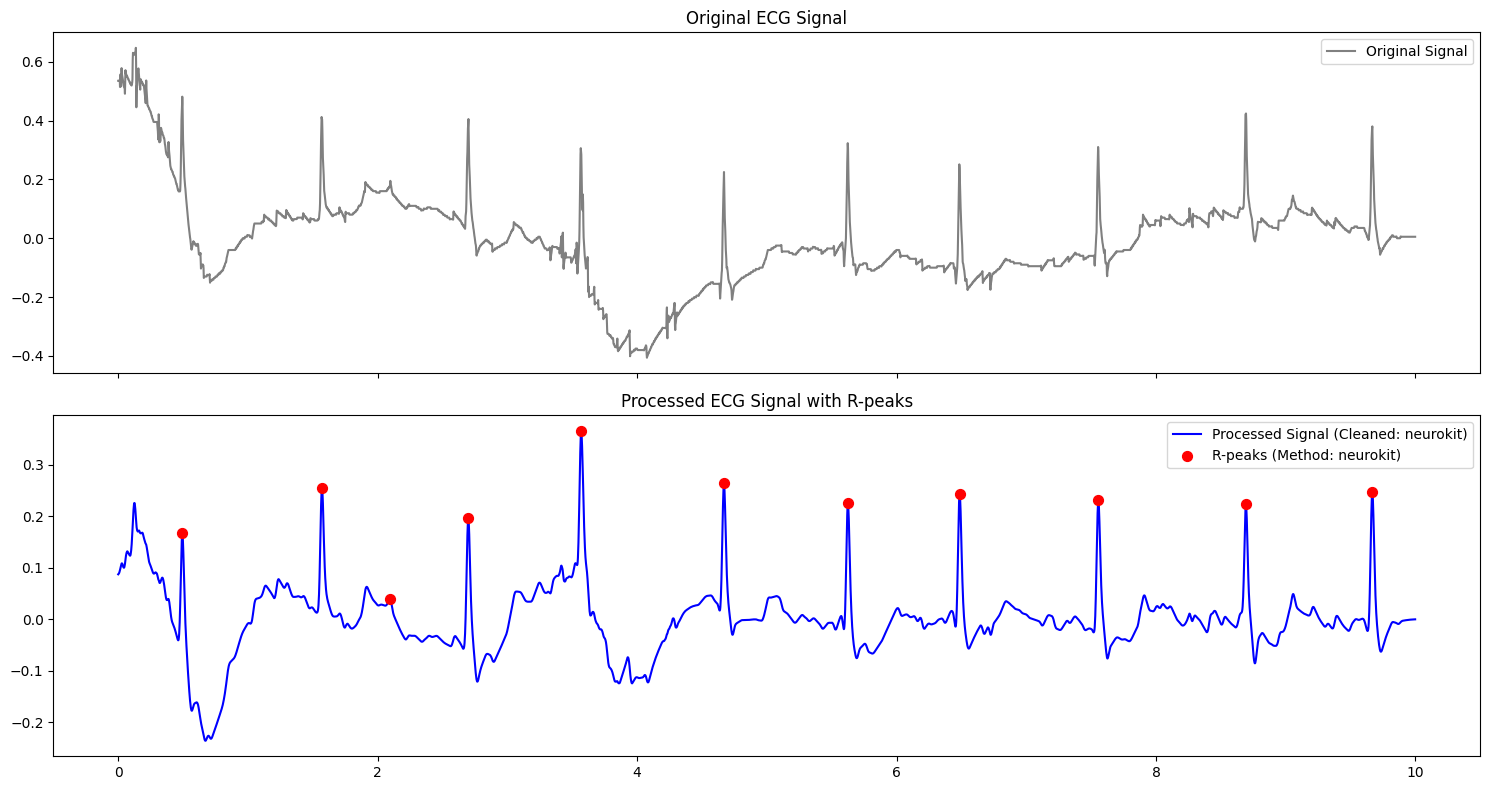


Attempting delineation with method: 'dwt'...
Delineation with 'dwt' did not yield valid QRS onsets/offsets.

Attempting delineation with method: 'cwt'...
Delineation with 'cwt' did not yield valid QRS onsets/offsets.

Attempting delineation with method: 'peak'...
Delineation with 'peak' did not yield valid QRS onsets/offsets.
All attempted delineation methods failed for Right Bundle Branch Block (03041_hr).
Attempting refined R-peak based QRS boundary estimation.
Refined Estimation QRS durations calculated.


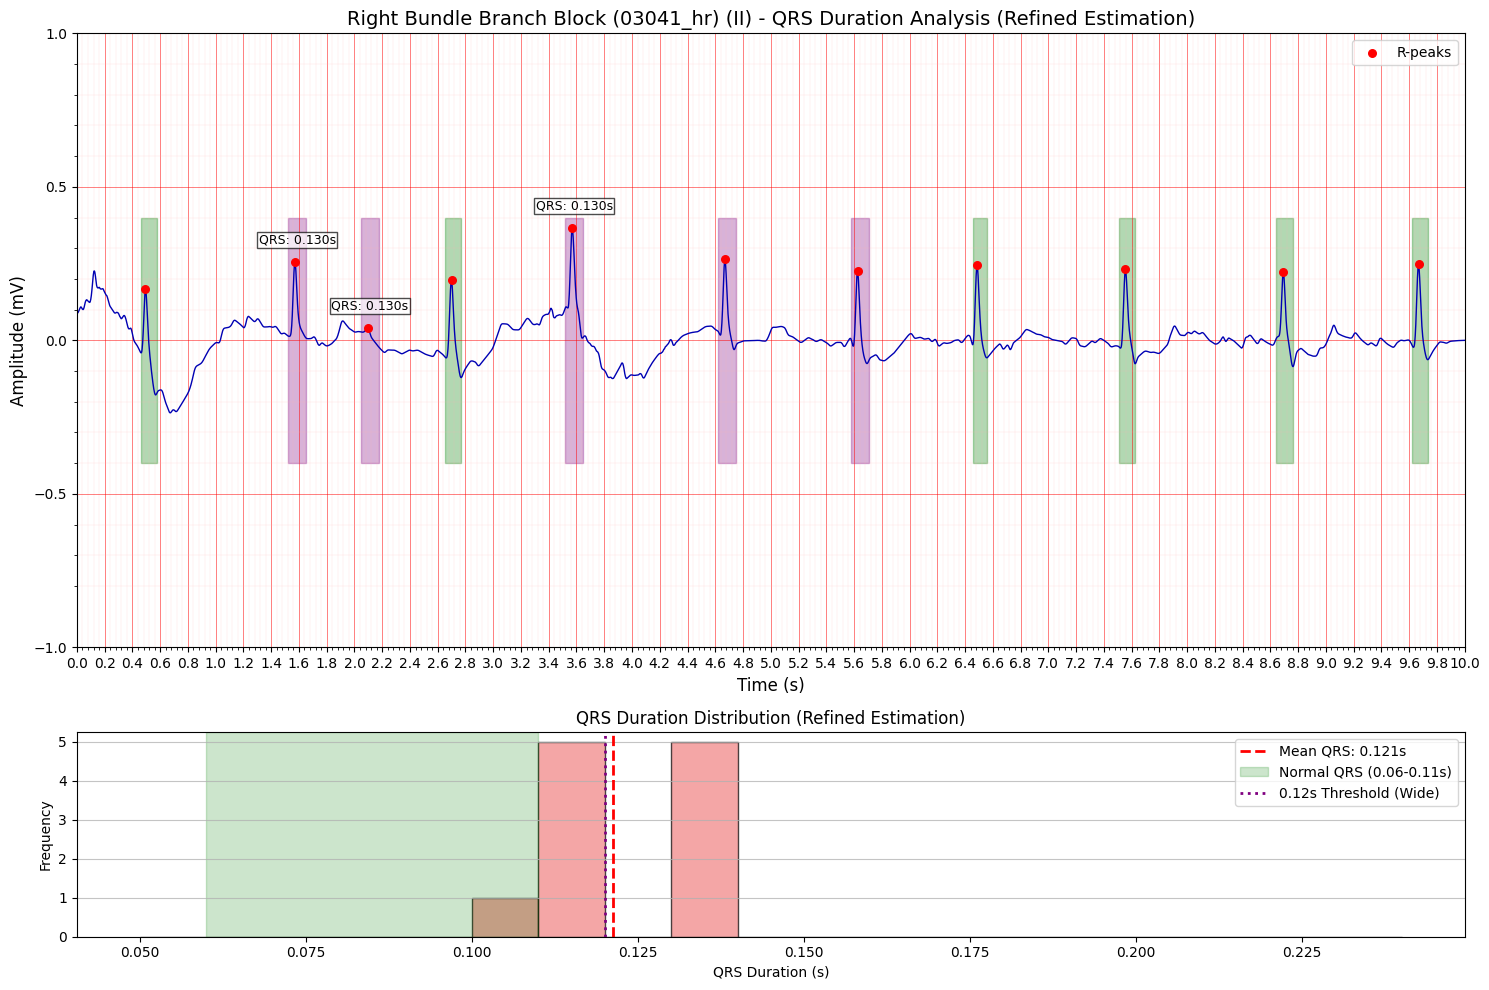


Clinical Observation for Right Bundle Branch Block (03041_hr) (II): QRS duration is considered prolonged if > 0.12 seconds (typically).
- QRS durations (Refined Estimation): Mean=0.121s, Min=0.100s, Max=0.130s.
- 5 out of 11 QRS durations (Refined Estimation) are > 0.12s.


In [4]:
# --- Visualization for Bundle Branch Blocks (Real Data) - WITH REFINED QRS ESTIMATION ATTEMPT ---
def visualize_bbb_real(ecg_signal, sampling_rate, abnormality_name, lead_name="Lead"):
    if ecg_signal is None: return

    # --- 1. Signal Cleaning ---
    cleaning_method_to_try = "neurokit"
    try:
        ecg_cleaned = nk.ecg_clean(ecg_signal, sampling_rate=sampling_rate, method=cleaning_method_to_try)
        print(f"Signal for {abnormality_name} cleaned using '{cleaning_method_to_try}' method.")
    except Exception as clean_e:
        print(f"Warning: Could not clean ECG signal for {abnormality_name} with method '{cleaning_method_to_try}': {clean_e}. Using raw signal.")
        ecg_cleaned = ecg_signal

    time_axis_orig = np.linspace(0, len(ecg_signal) / sampling_rate, len(ecg_signal), endpoint=False)
    time_axis_cleaned = np.linspace(0, len(ecg_cleaned) / sampling_rate, len(ecg_cleaned), endpoint=False)

    # --- 2. R-peak Detection (on cleaned signal) ---
    r_peak_indices_np = np.array([], dtype=int)
    rpeaks_for_delineation = None
    rpeak_method_to_try = "neurokit"
    try:
        _, rpeaks_detected_obj = nk.ecg_peaks(ecg_cleaned, sampling_rate=sampling_rate, method=rpeak_method_to_try)
        if 'ECG_R_Peaks' in rpeaks_detected_obj and rpeaks_detected_obj['ECG_R_Peaks'] is not None:
             r_peak_indices_np = rpeaks_detected_obj['ECG_R_Peaks']
             rpeaks_for_delineation = rpeaks_detected_obj
        print(f"R-peaks detected on cleaned signal using '{rpeak_method_to_try}' method. Found {r_peak_indices_np.size} R-peaks.")
    except Exception as rpeak_e:
        print(f"R-peak detection on cleaned signal failed with method '{rpeak_method_to_try}': {rpeak_e}")
        try:
            print("Attempting R-peak detection on raw signal as a fallback...")
            _, rpeaks_detected_obj = nk.ecg_peaks(ecg_signal, sampling_rate=sampling_rate, method=rpeak_method_to_try)
            if 'ECG_R_Peaks' in rpeaks_detected_obj and rpeaks_detected_obj['ECG_R_Peaks'] is not None:
                r_peak_indices_np = rpeaks_detected_obj['ECG_R_Peaks']
                rpeaks_for_delineation = rpeaks_detected_obj
            ecg_cleaned = ecg_signal
            time_axis_cleaned = time_axis_orig
            print(f"R-peaks detected on raw signal. Found {r_peak_indices_np.size} R-peaks. Proceeding with raw signal for delineation.")
        except Exception as rpeak_raw_e:
            print(f"R-peak detection on raw signal also failed: {rpeak_raw_e}")

    # --- Diagnostic Plot ---
    fig_diag, (ax_orig, ax_cleaned_diag) = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
    # ... (Diagnostic plot code from previous version - keeping it concise here) ...
    ax_orig.plot(time_axis_orig, ecg_signal, label="Original Signal", color='gray')
    ax_orig.set_title("Original ECG Signal"); ax_orig.legend(loc="upper right")
    ax_cleaned_diag.plot(time_axis_cleaned, ecg_cleaned, label=f"Processed Signal (Cleaned: {cleaning_method_to_try})", color='blue')
    if r_peak_indices_np.size > 0:
        ax_cleaned_diag.scatter(time_axis_cleaned[r_peak_indices_np], ecg_cleaned[r_peak_indices_np], color='red', marker='o', s=50, label=f'R-peaks (Method: {rpeak_method_to_try})', zorder=5)
    ax_cleaned_diag.set_title(f"Processed ECG Signal with R-peaks"); ax_cleaned_diag.legend(loc="upper right")
    plt.tight_layout(); plt.show(); plt.close(fig_diag)

    if r_peak_indices_np.size == 0:
        print(f"No R-peaks detected in {abnormality_name}. Cannot proceed."); # ... (plot and return) ...
        fig_f, ax_f = plt.subplots(figsize=(15,6)); plot_ecg_with_grid(time_axis_orig, ecg_signal, f'ECG {lead_name} - {abnormality_name} (No R-peaks detected)', ax_f, sampling_rate); plt.show(); plt.close(fig_f); return

    # --- 3. Delineation Attempt ---
    waves = None
    delineation_methods_to_try = ["dwt", "cwt", "peak"]
    successful_delineate_method = None
    for delineate_method in delineation_methods_to_try:
        print(f"\nAttempting delineation with method: '{delineate_method}'...")
        try:
            signals, waves_dict = nk.ecg_delineate(ecg_cleaned, rpeaks_for_delineation, sampling_rate=sampling_rate, method=delineate_method)
            waves = waves_dict
            if waves and 'ECG_QRS_Onsets' in waves and 'ECG_QRS_Offsets' in waves and \
               waves['ECG_QRS_Onsets'] is not None and waves['ECG_QRS_Offsets'] is not None and \
               np.sum(~np.isnan(waves['ECG_QRS_Onsets'])) > 0 and \
               np.sum(~np.isnan(waves['ECG_QRS_Offsets'])) > 0:
                print(f"Delineation successful with method '{delineate_method}'. Found QRS onsets/offsets.")
                successful_delineate_method = delineate_method
                break
            else: print(f"Delineation with '{delineate_method}' did not yield valid QRS onsets/offsets."); waves = None
        except Exception as e: print(f"Delineation with method '{delineate_method}' failed: {e}"); waves = None

    if waves is None: print(f"All attempted delineation methods failed for {abnormality_name}.")

    qrs_onsets_delineated, qrs_offsets_delineated = [], []
    if waves:
        if 'ECG_QRS_Onsets' in waves and waves['ECG_QRS_Onsets'] is not None: qrs_onsets_delineated = [int(q) for q in waves['ECG_QRS_Onsets'] if not np.isnan(q)]
        if 'ECG_QRS_Offsets' in waves and waves['ECG_QRS_Offsets'] is not None: qrs_offsets_delineated = [int(q) for q in waves['ECG_QRS_Offsets'] if not np.isnan(q)]

    qrs_durations_sec, highlight_regions_qrs = [], []
    estimation_type = "Delineated" # Default type

    # --- 4. Calculate QRS Durations (from delineation or estimation) ---
    if qrs_onsets_delineated and qrs_offsets_delineated:
        offset_search_idx = 0
        for q_onset in qrs_onsets_delineated:
            # ... (matching logic from previous version - keeping it concise here) ...
            found_offset = False; temp_offset_search_idx = offset_search_idx
            while temp_offset_search_idx < len(qrs_offsets_delineated):
                q_offset = qrs_offsets_delineated[temp_offset_search_idx]
                if q_offset > q_onset:
                    duration_sec = (q_offset - q_onset) / sampling_rate
                    if 0.02 < duration_sec < 0.35: qrs_durations_sec.append(duration_sec); highlight_regions_qrs.append((q_onset, q_offset)); offset_search_idx = temp_offset_search_idx + 1; found_offset = True; break
                temp_offset_search_idx +=1
            if not found_offset and temp_offset_search_idx >= len(qrs_offsets_delineated): break
        if not qrs_durations_sec:
             print(f"Delineation provided onsets/offsets (method: {successful_delineate_method}), but no valid QRS durations could be matched/calculated.")

    if not qrs_durations_sec: # If delineation failed or yielded no durations, try refined estimation
        estimation_type = "Refined Estimation"
        print(f"Attempting refined R-peak based QRS boundary estimation.")

        # --- Refined Estimation Parameters (NEEDS TUNING) ---
        prominence_factor = 0.05 # Percentage of peak-to-peak amplitude for prominence
        min_peak_width = 1       # Minimum width for find_peaks
        q_search_sec = 0.10      # How far left of R-peak to search for Q-like point
        s_search_sec = 0.15      # How far right of R-peak to search for S-like point/J-point
        # Fallback if local features not found (relative to R-peak)
        q_fallback_sec = 0.05
        s_fallback_sec = 0.08 # For RBBB/LBBB, S part can be longer
        if "LBBB" in abnormality_name: s_fallback_sec = 0.09
        # --- End of Refined Estimation Parameters ---

        signal_ptp = np.max(ecg_cleaned) - np.min(ecg_cleaned)
        prominence_threshold = prominence_factor * signal_ptp
        if signal_ptp == 0 : prominence_threshold = 0.01 # Avoid zero prominence if signal is flat

        for r_idx in r_peak_indices_np:
            # --- QRS Start Estimation (Refined) ---
            search_window_left_samples = int(q_search_sec * sampling_rate)
            start_search_idx_left = max(0, r_idx - search_window_left_samples)
            segment_left = ecg_cleaned[start_search_idx_left : r_idx]
            qrs_start_est = max(0, r_idx - int(q_fallback_sec * sampling_rate)) # Fallback
            if segment_left.size > min_peak_width + 1:
                inv_segment_left = -segment_left
                peaks_in_inv_left, _ = find_peaks(inv_segment_left, prominence=prominence_threshold, width=min_peak_width)
                if peaks_in_inv_left.size > 0:
                    qrs_start_est = start_search_idx_left + peaks_in_inv_left[-1] # Closest to R

            # --- QRS End Estimation (Refined) ---
            search_window_right_samples = int(s_search_sec * sampling_rate)
            # Ensure r_idx+1 is within bounds before slicing
            actual_r_idx_plus_1 = min(r_idx + 1, len(ecg_cleaned) -1)
            end_search_idx_right = min(len(ecg_cleaned), actual_r_idx_plus_1 + search_window_right_samples)
            segment_right = ecg_cleaned[actual_r_idx_plus_1 : end_search_idx_right]
            qrs_end_est = min(len(ecg_cleaned) -1, r_idx + int(s_fallback_sec * sampling_rate)) # Fallback
            if segment_right.size > min_peak_width + 1:
                inv_segment_right = -segment_right # For S-wave (local minimum)
                peaks_in_inv_right, _ = find_peaks(inv_segment_right, prominence=prominence_threshold, width=min_peak_width)
                if peaks_in_inv_right.size > 0:
                    qrs_end_est = actual_r_idx_plus_1 + peaks_in_inv_right[0] # Closest to R
                else: # If no clear S, try to find J-point like feature (end of rapid deflection)
                      # This is harder. For now, rely on fallback or fixed extension.
                      # A simple J-point heuristic: where slope decreases significantly after S or R'
                      # Or where the signal starts to flatten towards ST segment.
                      # For simplicity, the fallback is used if no S-like minimum is found.
                      pass


            if qrs_start_est >= qrs_end_est: # If estimation is tangled, use simple symmetric fallback
                estimation_type = "Symmetric Estimation (Fallback)"
                print(f"Refined estimation for beat at R-peak {r_idx} tangled, using symmetric fallback.")
                default_qrs_ms = 130 if "RBBB" in abnormality_name else 150
                half_qrs_samples_fallback = (int((default_qrs_ms / 1000.0) * sampling_rate)) // 2
                qrs_start_est = max(0, r_idx - half_qrs_samples_fallback)
                qrs_end_est = min(len(ecg_cleaned) - 1, r_idx + half_qrs_samples_fallback)

            actual_est_duration_samples = qrs_end_est - qrs_start_est
            if actual_est_duration_samples > 0:
                qrs_durations_sec.append(actual_est_duration_samples / sampling_rate)
                highlight_regions_qrs.append((qrs_start_est, qrs_end_est))

        if qrs_durations_sec: print(f"{estimation_type} QRS durations calculated.")
        else: print(f"Could not perform {estimation_type} for QRS durations."); estimation_type = "Failed Estimation"

    # --- 5. Plotting Results ---
    title_suffix = f" ({estimation_type})" if estimation_type != "Delineated" else f" (Delineated: {successful_delineate_method or 'N/A'})"
    fig_main, axes_main = plt.subplots(2, 1, figsize=(15, 10), gridspec_kw={'height_ratios': [3, 1]})
    plot_ecg_with_grid(time_axis_cleaned, ecg_cleaned, f'{abnormality_name} ({lead_name}) - QRS Duration Analysis{title_suffix}', axes_main[0], sampling_rate)
    # ... (Plotting R-peaks, QRS highlights, text annotations - same as previous version, ensure using r_peak_indices_np and ecg_cleaned) ...
    if r_peak_indices_np.size > 0:
        axes_main[0].scatter(time_axis_cleaned[r_peak_indices_np], ecg_cleaned[r_peak_indices_np], c='r', marker='o', s=30, label='R-peaks', zorder=5)
    annotated_count = 0
    if highlight_regions_qrs:
        for q_on_idx, q_off_idx in highlight_regions_qrs:
            dur = (q_off_idx - q_on_idx) / sampling_rate
            color = 'purple' if dur > 0.12 else ('green' if dur >= 0.06 else 'lightgray')
            axes_main[0].axvspan(time_axis_cleaned[q_on_idx], time_axis_cleaned[q_off_idx], alpha=0.3, color=color, ymin=0.3, ymax=0.7)
            if annotated_count < 3 and dur > 0.12:
                text_y_start_idx = max(0, q_on_idx); text_y_end_idx = min(len(ecg_cleaned) -1, q_off_idx)
                if text_y_start_idx <= text_y_end_idx :
                    text_y_val = np.max(ecg_cleaned[text_y_start_idx : text_y_end_idx+1] )
                    axes_main[0].text((time_axis_cleaned[q_on_idx] + time_axis_cleaned[q_off_idx])/2, text_y_val + 0.1 * (np.max(ecg_cleaned) - np.min(ecg_cleaned)), f'QRS: {dur:.3f}s', ha='center', c='k', fontsize=9, bbox=dict(fc='w', alpha=0.7, pad=1)); annotated_count += 1
    axes_main[0].legend(loc='upper right')

    if qrs_durations_sec:
        # ... (Histogram plotting - same as previous, ensure using title_suffix) ...
        max_hist_val = np.max(qrs_durations_sec) if qrs_durations_sec else 0.20; min_hist_val = np.min(qrs_durations_sec) if qrs_durations_sec else 0.05
        hist_range_min = min(0.05, min_hist_val - 0.01 if min_hist_val > 0.05 else 0.04); hist_range_max = max(0.25, max_hist_val + 0.02)
        hist_bins = np.arange(hist_range_min, hist_range_max, 0.01)
        if not hist_bins.size: hist_bins = 'auto'
        axes_main[1].hist(qrs_durations_sec, bins=hist_bins, ec='k', alpha=0.7, color='lightcoral')
        mean_qrs = np.mean(qrs_durations_sec); axes_main[1].axvline(mean_qrs, c='r', ls='--', lw=2, label=f'Mean QRS: {mean_qrs:.3f}s')
        axes_main[1].axvspan(0.06, 0.11, color='g', alpha=0.2, label='Normal QRS (0.06-0.11s)'); axes_main[1].axvline(0.12, c='purple', ls=':', lw=2, label='0.12s Threshold (Wide)')
        axes_main[1].set_title(f'QRS Duration Distribution{title_suffix}'); axes_main[1].set_xlabel('QRS Duration (s)'); axes_main[1].set_ylabel('Frequency'); axes_main[1].legend(); axes_main[1].grid(axis='y', alpha=0.75)
    else:
        axes_main[1].text(0.5, 0.5, "No QRS durations calculated / to display.", ha='center');
        axes_main[1].set_title(f'QRS Duration Distribution{title_suffix}')

    plt.tight_layout(); plt.show(); plt.close(fig_main)

    print(f"\nClinical Observation for {abnormality_name} ({lead_name}): QRS duration is considered prolonged if > 0.12 seconds (typically).")
    # ... (Clinical observation text - same as previous, ensure using estimation_type) ...
    if qrs_durations_sec:
        num_wide = sum(1 for qrs_d in qrs_durations_sec if qrs_d > 0.12)
        print(f"- QRS durations ({estimation_type}): Mean={np.mean(qrs_durations_sec):.3f}s, Min={np.min(qrs_durations_sec):.3f}s, Max={np.max(qrs_durations_sec):.3f}s.")
        print(f"- {num_wide} out of {len(qrs_durations_sec)} QRS durations ({estimation_type}) are > 0.12s.")
    else: print("- No QRS durations could be reliably calculated or estimated.")

# ─────────────────────────────────────
# 2. RBBB 可视化
# ─────────────────────────────────────
import numpy as np, matplotlib.pyplot as plt, neurokit2 as nk
from scipy.signal import find_peaks

# -----------------------------------------------
# 小工具：心电纸网格 + R 峰
# -----------------------------------------------
def _plot_lead(t, sig, fs, title, ax, r_idx=None):
    plot_ecg_with_grid(t, sig, title, ax, fs, show_grid=True, style="color")
    if r_idx is not None and len(r_idx):
        ax.scatter(t[r_idx], sig[r_idx], c="red", s=30, zorder=5)

# -----------------------------------------------
# 主函数
# -----------------------------------------------
def visualize_rbbb_real(record_name, db_dir=None, verbose=True):
    """一键 RBBB 筛查：自动绘制 V1/V2/V6 并输出形态 & QRS 分析。"""

    # 1. 读取信号
    need = ["V1", "V2", "V6", "I"]
    leads   = load_wfdb_signals(record_name, leads=need, db_dir=db_dir,
                                allow_missing=True)   # ← 上一步修过
    if ("V1" not in leads) or ("V2" not in leads):
        print("缺少 V1/V2，无法完整评估 RBBB。")
        return
    if "V6" not in leads:
        leads["V6"] = leads.get("I")          # 用 I 替补

    # 2. 遍历分析
    summary = []
    qrs_pool = []
    rsr_detected = False
    wide_s_detected = False

    fig, axes = plt.subplots(len(leads), 1, figsize=(15, 3.5*len(leads)),
                             sharex=True)
    if len(leads) == 1:
        axes = [axes]

    for ax, (lead, (sig, fs)) in zip(axes, leads.items()):
        t = np.linspace(0, len(sig)/fs, len(sig), endpoint=False)

        # R-peaks
        _, rp = nk.ecg_peaks(sig, sampling_rate=fs, method="neurokit")
        r_idx = rp["ECG_R_Peaks"]

        # ---------------- QRS 宽度 -----------------
        win = int(0.06*fs)          # ±60 ms 粗估
        qrs_local = []
        for r in r_idx:
            on  = max(0,  r - win)
            off = min(len(sig)-1, r + win)
            qrs_local.append((off-on)/fs)
        qrs_pool.extend(qrs_local)

        # ---------------- rsR′ 检测 (仅 V1/V2) -----
        if lead in ["V1", "V2"]:
            for r in r_idx:
                # 在 r 峰后 120 ms 内找第二个正峰
                seg = sig[r:r+int(0.12*fs)]
                pks, _ = find_peaks(seg, distance=fs*0.02)  # ≥20 ms
                if len(pks) >= 2:
                    r1_amp = seg[pks[0]]
                    r2_amp = seg[pks[1]]
                    if r2_amp > 0.3*r1_amp:     # R′ 足够高
                        rsr_detected = True
                        break

        # ---------------- V6 深宽 S 波检 (左导联) ----
        if lead in ["V6", "I"]:
            for r in r_idx:
                seg = sig[r:r+int(0.12*fs)]
                valleys, _ = find_peaks(-seg)
                if len(valleys):
                    s_amp = -seg[valleys[0]]
                    if s_amp > 0.05:            # >0.05 mV 深
                        wide_s_detected = True
                        break

        # ---------------- 绘图 ---------------------
        _plot_lead(t, sig, fs, f"{lead} – RBBB screening ({record_name})",
                   ax, r_idx)

    plt.tight_layout(); plt.show()

    # 3. QRS 直方图
    if qrs_pool:
        qrs_pool = np.array(qrs_pool)
        plt.figure(figsize=(6,3))
        plt.hist(qrs_pool, bins="auto", ec='k', alpha=0.75)
        plt.axvline(0.12, c='purple', ls='--', lw=2, label="0.12 s")
        plt.title("QRS duration distribution"); plt.xlabel("s"); plt.ylabel("Count")
        plt.grid(axis="y", alpha=0.5); plt.legend(); plt.tight_layout(); plt.show()
        qrs_mean = qrs_pool.mean(); prop_wide = np.mean(qrs_pool > 0.12)
    else:
        qrs_mean = np.nan; prop_wide = np.nan

    # 4. 文本报告
    print("▸ 记录:", record_name)
    print(f"▸ 平均 QRS 宽度: {qrs_mean:.3f} s  "
          f"（>0.12 s 占 {prop_wide*100:.1f}%）")
    print("▸ V1/V2 存在 rsR′/M 型:", "是" if rsr_detected else "否")
    print("▸ V6/I 存在宽深 S 波:", "是" if wide_s_detected else "否")
    print("\n简易结论：",
          "满足 RBBB 三要素 → 考虑 RBBB" if (qrs_mean>0.12 and rsr_detected and wide_s_detected)
          else "形态不完全符合，建议人工复核")



# --- RBBB Visualization ---
rbbb_filename = "03041_hr"
rbbb_lead_index = 1 # Assuming Lead II
# For ltstdb records, pn_dir is 'ltstdb/'
# If your file is local, set rbbb_pn_dir = None
rbbb_pn_dir = None # Example: Long Term ST Database (check if this record exists there with this name)


print(f"--- Processing RBBB: {rbbb_filename} ---")
ecg_rbbb, fs_rbbb, lead_name_rbbb = load_wfdb_signal(rbbb_filename, rbbb_lead_index, db_dir=rbbb_pn_dir)

if ecg_rbbb is not None and fs_rbbb is not None:
    # Optional: Truncate signal
    # max_display_sec = 15
    # if len(ecg_rbbb) > fs_rbbb * max_display_sec:
    #     ecg_rbbb = ecg_rbbb[:fs_rbbb * max_display_sec]
    #     print(f"Signal truncated to {max_display_sec}s for display.")

    visualize_bbb_real(ecg_rbbb, fs_rbbb,
                       abnormality_name=f"Right Bundle Branch Block ({rbbb_filename})",
                       lead_name=lead_name_rbbb)
else:
    print(f"Could not load data for RBBB: {rbbb_filename}")

# rbbb_filename = "03041_hr"     # 改成你的真实 WFDB 记录名
# rbbb_pn_dir   = None           # 若在 PhysioNet 远程库就写对应目录

# visualize_rbbb_real(rbbb_filename, db_dir=rbbb_pn_dir)

--- Processing 1st Degree AV Block: 01484_hr ---
Loaded 01484_hr, Lead: II, Sampling Rate: 500 Hz, Length: 5000 samples
Signal cleaned with NeuroKit.
Detected 9 R-peaks.
✓ delineation success via 'prominence'.


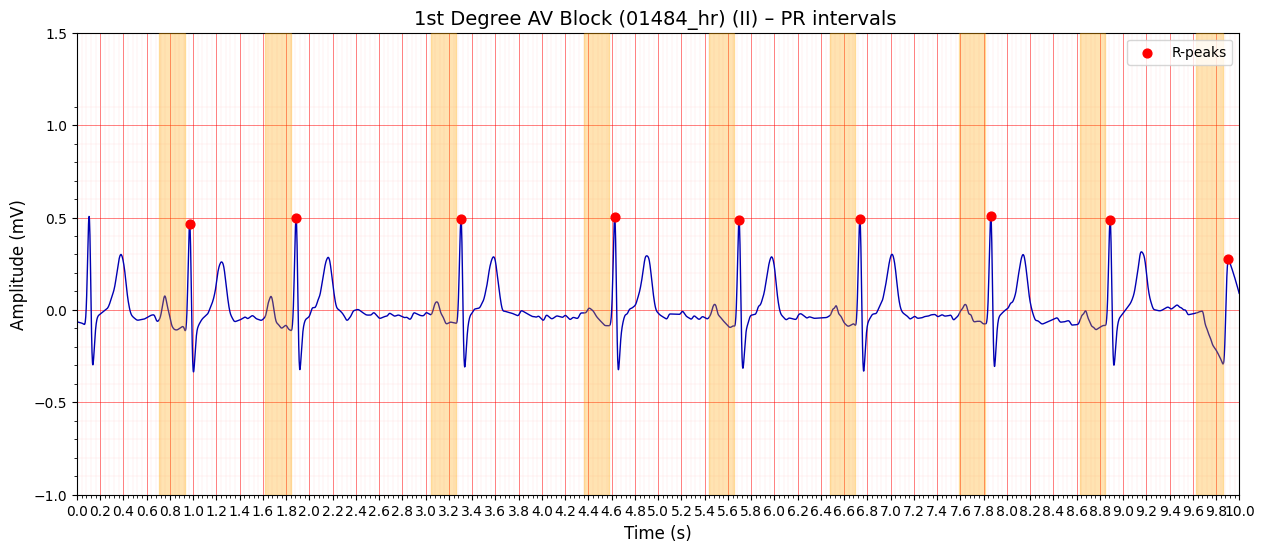

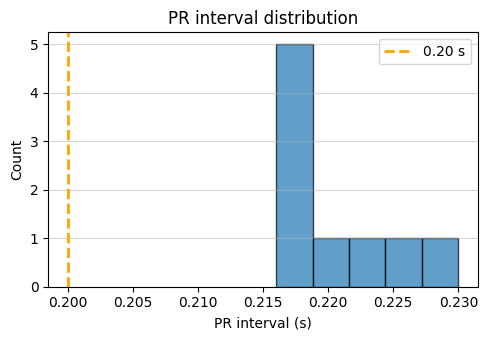

Computed 9 PR intervals (mean 0.220 s). 9 longer than 0.20 s.

Clinical Observation for 1st Degree AV Block (01484_hr) (II):
- PR interval is prolonged if > 0.20 seconds (5 small squares at 25mm/s).
- Calculated PR intervals: Mean=0.220s, Min=0.216s, Max=0.230s.
- 9 out of 9 (100.0%) calculated PR intervals are > 0.20s.
  - The histogram for this segment shows PR intervals consistently above the 0.20s threshold, characteristic of 1st Degree AV Block.
- In 1st Degree AV Block, each P-wave is typically followed by a QRS complex, and the rhythm is often regular.


In [5]:
# --- Visualization for 1st Degree AV Block (Real Data) - CORRECTED & ENHANCED ---
def visualize_1davb_real(
    ecg_signal,
    sampling_rate,
    ecg_title="1st-degree AV Block",
    lead_name="Lead II",
    verbose=True,
):
    # 0. 基础检查
    if ecg_signal is None or len(ecg_signal) == 0:
        print("Empty ECG signal — aborting.")
        return

    # 1. 清理
    try:
        ecg_clean = nk.ecg_clean(ecg_signal, sampling_rate=sampling_rate, method="neurokit")
        if verbose:
            print(f"Signal cleaned with NeuroKit.")
    except Exception as e:
        print(f"Cleaning failed ({e}) — using raw signal.")
        ecg_clean = ecg_signal

    # 2. R-peak
    _, rdict = nk.ecg_peaks(ecg_clean, sampling_rate=sampling_rate, method="neurokit")
    r_idx = np.asarray(rdict["ECG_R_Peaks"], dtype=int)
    if len(r_idx) < 2:
        print("Not enough R-peaks detected.")
        return
    if verbose:
        print(f"Detected {len(r_idx)} R-peaks.")

    # 3. Delineation（prominence → dwt → cwt → peak）
    waves, used_method = None, None
    for m in ["prominence", "dwt", "cwt", "peak"]:
        try:
            _, w = nk.ecg_delineate(
                ecg_clean,
                rpeaks=r_idx,
                sampling_rate=sampling_rate,
                method=m,
            )
            w = {k.lower(): v for k, v in w.items()}
            if (
                np.nansum(~np.isnan(_waves_get(w, "ecg_p_onsets"))) > 0
                and np.nansum(~np.isnan(_waves_get(w, "ecg_r_onsets"))) > 0
            ):
                waves, used_method = w, m
                if verbose:
                    print(f"✓ delineation success via '{m}'.")
                break
            if verbose:
                print(f"× '{m}' gave no valid P / R onsets.")
        except Exception as e:
            if verbose:
                print(f"× '{m}' failed ({e}).")

    if waves is None:
        print("All delineation methods failed — cannot compute PR.")
        return

    # 4. 提取 PR 间期
    p_on = np.asarray(_waves_get(waves, "ecg_p_onsets"), dtype=float)
    r_on = np.asarray(_waves_get(waves, "ecg_r_onsets"), dtype=float)
    p_on = p_on[~np.isnan(p_on)].astype(int)
    r_on = r_on[~np.isnan(r_on)].astype(int)

    pr_intervals, highlight = [], []
    r_ptr = 0
    for p in p_on:
        while r_ptr < len(r_on) and r_on[r_ptr] <= p:
            r_ptr += 1
        if r_ptr >= len(r_on):
            break
        r = r_on[r_ptr]
        pr = (r - p) / sampling_rate
        if 0.05 < pr < 0.6:                        # 有效范围
            pr_intervals.append(pr)
            highlight.append((p, r))

    if len(pr_intervals) == 0:
        print("Delineation ok but no PR intervals within 0.05–0.6 s.")
        return
    pr_intervals = np.array(pr_intervals)

    # 5. 绘图
    t = np.linspace(0, len(ecg_clean) / sampling_rate, len(ecg_clean), endpoint=False)

    # --- 心电纸网格主图 ---
    fig, ax = plt.subplots(figsize=(15, 6))
    plot_ecg_with_grid(
        t,
        ecg_clean,
        f"{ecg_title} ({lead_name}) – PR intervals ",
        ax,
        sampling_rate,
        show_grid=True,
        style="color",          # 设为 "bw" 可切黑白
    )
    ax.scatter(t[r_idx], ecg_clean[r_idx], c="red", s=40, label="R-peaks", zorder=5)
    for (p, r) in highlight:
        ax.axvspan(
            t[p], t[r],
            alpha=0.3,
            color=("orange" if (r - p)/sampling_rate > 0.20 else "green"),
            zorder=4,
        )
    ax.legend(loc="upper right")
    plt.show()

    # --- PR 直方图 ---
    plt.figure(figsize=(5, 3.5))
    plt.hist(pr_intervals, bins="auto", edgecolor="k", alpha=0.7)
    plt.axvline(0.20, color="orange", ls="--", lw=2, label="0.20 s")
    plt.grid(axis="y", alpha=0.5)
    plt.xlabel("PR interval (s)")
    plt.ylabel("Count")
    plt.title("PR interval distribution")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 6. 文本摘要
    print(
        f"Computed {len(pr_intervals)} PR intervals "
        f"(mean {pr_intervals.mean():.3f} s). "
        f"{np.sum(pr_intervals > 0.20)} longer than 0.20 s."
    )
    print_observation_1davb(
        pr_intervals=pr_intervals,
        used_delineation_method=used_method, # Pass the method that was successful
        ecg_title=ecg_title,
        lead_name=lead_name,
        sampling_rate=sampling_rate # Pass sampling_rate if needed by observation function
    )

# --- 1st Degree AV Block Visualization ---
avb1_filename = "01484_hr"
avb1_lead_index = 1 # Assuming Lead II
# For ltstdb records, pn_dir is 'ltstdb/'
# If your file is local, set avb1_pn_dir = None
avb1_pn_dir = None # Example: Long Term ST Database (check if this record exists there with this name)

print(f"--- Processing 1st Degree AV Block: {avb1_filename} ---")
ecg_avb1, fs_avb1, lead_name_avb1 = load_wfdb_signal(avb1_filename, avb1_lead_index, db_dir=avb1_pn_dir)

if ecg_avb1 is not None and fs_avb1 is not None:
    # Optional: Truncate signal
    # max_display_sec = 20
    # if len(ecg_avb1) > fs_avb1 * max_display_sec:
    #     ecg_avb1 = ecg_avb1[:fs_avb1 * max_display_sec]
    #     print(f"Signal truncated to {max_display_sec}s for display.")

    visualize_1davb_real(ecg_avb1, fs_avb1,
                         ecg_title=f"1st Degree AV Block ({avb1_filename})",
                         lead_name=lead_name_avb1)
else:
    print(f"Could not load data for 1st Degree AV Block: {avb1_filename}")

--- Processing Sinus Tachycardia: 04408_hr ---
Loaded 04408_hr, Lead: II, Sampling Rate: 500 Hz, Length: 5000 samples
Signal for Sinus Tachycardia (04408_hr) cleaned.


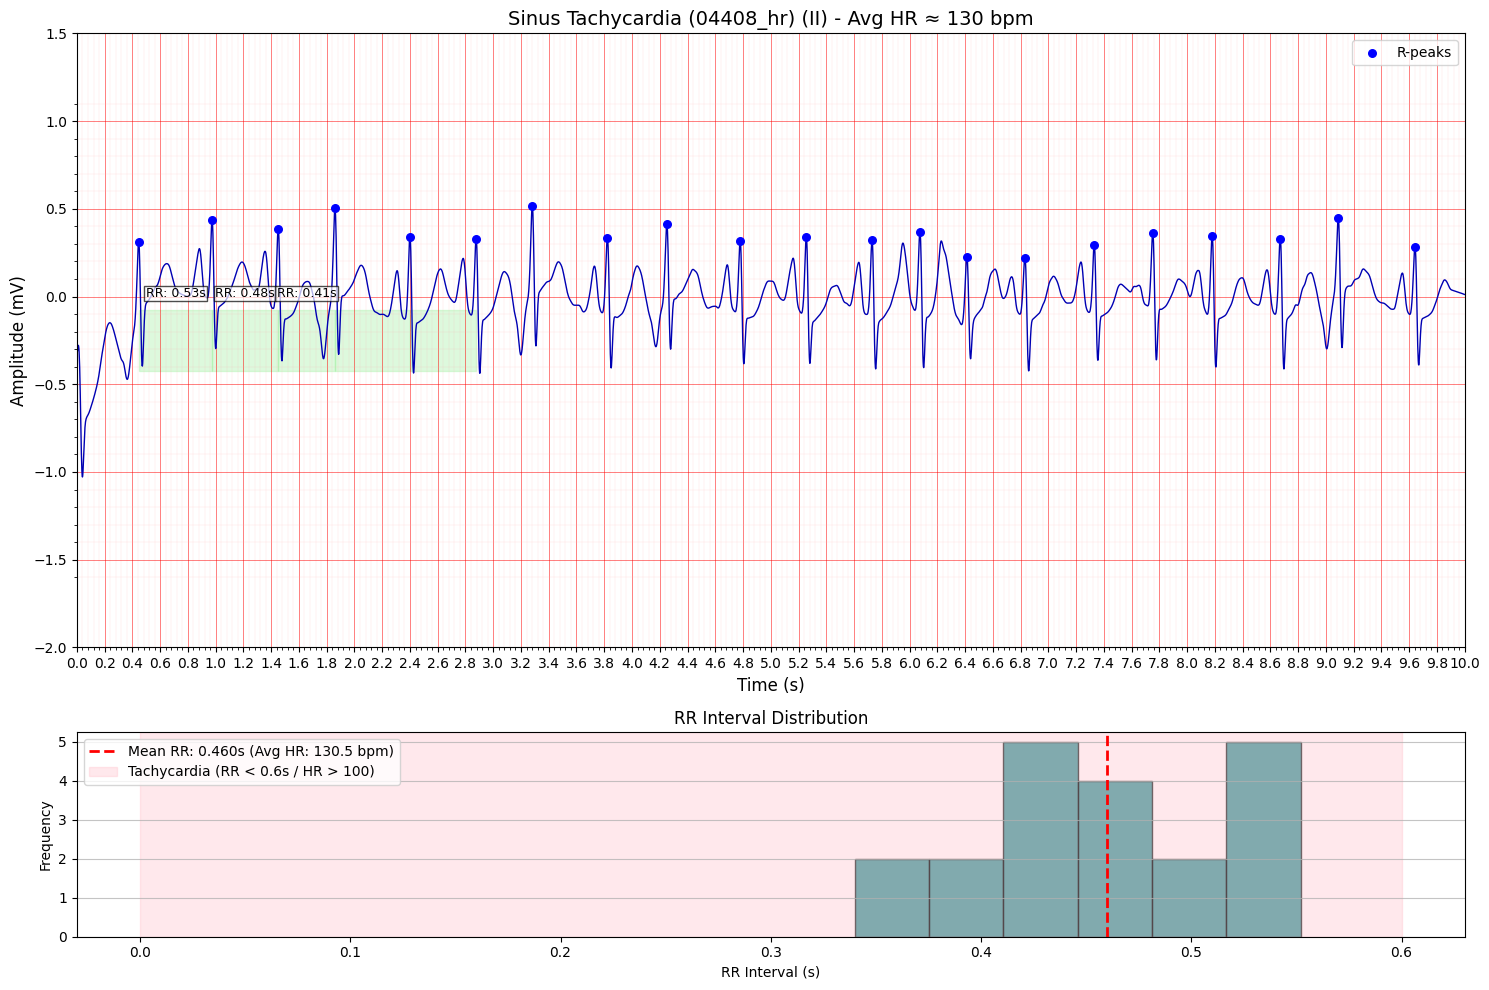


Obs for Sinus Tachycardia (04408_hr) (II):
- HR > 100 bpm. Avg: 130.5 bpm. RR intervals < 0.6s.
- For Sinus rhythms, P waves normal & precede QRS. Rhythm regular.


In [7]:
# --- Visualization for Sinus Tachycardia (Real Data) - Includes plt.close() ---
def visualize_sinus_rhythm_rate_real(ecg_signal, sampling_rate, abnormality_name, lead_name="Lead"):
    if ecg_signal is None: return
    # Sinus rhythms are less likely to need aggressive cleaning affecting P-waves,
    # but basic cleaning can still be beneficial for R-peak detection.
    try:
        ecg_cleaned = nk.ecg_clean(ecg_signal, sampling_rate=sampling_rate, method="neurokit")
        print(f"Signal for {abnormality_name} cleaned.")
    except Exception as clean_e: print(f"Warning: Could not clean ECG for {abnormality_name}: {clean_e}. Using raw."); ecg_cleaned = ecg_signal

    time_axis = np.linspace(0, len(ecg_cleaned) / sampling_rate, len(ecg_cleaned), endpoint=False)
    r_peak_indices = []
    try:
        _, rpeaks = nk.ecg_peaks(ecg_cleaned, sampling_rate=sampling_rate)
        r_peak_indices = rpeaks['ECG_R_Peaks']
    except Exception as e:
        print(f"R-peak detection failed for {abnormality_name}: {e}")
        fig_f, ax_f = plt.subplots(figsize=(15,6)); plot_ecg_with_grid(time_axis, ecg_cleaned, f'ECG {lead_name} - {abnormality_name} (R-peak detection Failed)', ax_f, sampling_rate); plt.show(); plt.close(fig_f); return

    if len(r_peak_indices) < 2:
        print(f"Not enough R-peaks for RR analysis in {abnormality_name}.")
        fig_f, ax_f = plt.subplots(figsize=(15,6)); plot_ecg_with_grid(time_axis, ecg_cleaned, f'ECG {lead_name} - {abnormality_name} (Few R-peaks)', ax_f, sampling_rate)
        if len(r_peak_indices) > 0: ax_f.scatter(time_axis[r_peak_indices], ecg_cleaned[r_peak_indices], c='b', marker='o', s=30, label='R-peaks'); ax_f.legend()
        plt.show(); plt.close(fig_f); return

    rr_intervals_sec = np.diff(r_peak_indices) / sampling_rate
    avg_hr = 60.0 / np.mean(rr_intervals_sec) if len(rr_intervals_sec) > 0 else float('nan')

    fig, axes = plt.subplots(2, 1, figsize=(15, 10), gridspec_kw={'height_ratios': [3, 1]})
    plot_ecg_with_grid(time_axis, ecg_cleaned, f'{abnormality_name} ({lead_name}) - Avg HR ≈ {avg_hr:.0f} bpm', axes[0], sampling_rate)
    axes[0].scatter(time_axis[r_peak_indices], ecg_cleaned[r_peak_indices], c='b', marker='o', s=30, label='R-peaks', zorder=5)
    for i in range(min(len(r_peak_indices) - 1, 5)):
        start_idx, end_idx = r_peak_indices[i], r_peak_indices[i+1]
        axes[0].axvspan(time_axis[start_idx], time_axis[end_idx], alpha=0.3, color='lightgreen', ymin=0.45, ymax=0.55)
        if i < 3: axes[0].text(time_axis[(start_idx + end_idx) // 2], np.median(ecg_cleaned), f'RR: {rr_intervals_sec[i]:.2f}s', ha='center', c='k', fontsize=9, bbox=dict(fc='w', alpha=0.7, pad=1))
    axes[0].legend(loc='upper right')
    if len(rr_intervals_sec) > 0:
        axes[1].hist(rr_intervals_sec, bins='auto', ec='k', alpha=0.7, color='teal')
        mean_rr = np.mean(rr_intervals_sec); axes[1].axvline(mean_rr, c='r', ls='--', lw=2, label=f'Mean RR: {mean_rr:.3f}s (Avg HR: {60/mean_rr:.1f} bpm)')
        if "Tachycardia" in abnormality_name: axes[1].axvspan(0, 0.6, color='lightpink', alpha=0.3, label='Tachycardia (RR < 0.6s / HR > 100)')
        axes[1].set_title('RR Interval Distribution'); axes[1].set_xlabel('RR Interval (s)'); axes[1].set_ylabel('Frequency'); axes[1].legend(); axes[1].grid(axis='y', alpha=0.75)
    else: axes[1].text(0.5, 0.5, "No RR intervals.", ha='center'); axes[1].set_title('RR Interval Distribution')
    plt.tight_layout(); plt.show(); plt.close(fig)
    print(f"\nObs for {abnormality_name} ({lead_name}):")
    if "Tachycardia" in abnormality_name: print(f"- HR > 100 bpm. Avg: {avg_hr:.1f} bpm. RR intervals < 0.6s.")
    print(f"- For Sinus rhythms, P waves normal & precede QRS. Rhythm regular.")


# --- Sinus Tachycardia Visualization ---
st_filename = "04408_hr" # This looks like a record name from EDB (European ST-T Database) or similar
st_lead_index = 1      # Assuming Lead II
# For European ST-T Database, pn_dir='edb/'
# If your file is local, set st_pn_dir = None
# ltstdb also has _lr files, let's try that as per previous guesses for _lr
st_pn_dir = None # Or 'edb/' if it's from there. Please verify.


print(f"--- Processing Sinus Tachycardia: {st_filename} ---")
ecg_st, fs_st, lead_name_st = load_wfdb_signal(st_filename, st_lead_index, db_dir=st_pn_dir)

if ecg_st is not None and fs_st is not None:
    # Optional: Truncate signal
    # max_display_sec = 15
    # if len(ecg_st) > fs_st * max_display_sec:
    #     ecg_st = ecg_st[:fs_st * max_display_sec]
    #     print(f"Signal truncated to {max_display_sec}s for display.")

    visualize_sinus_rhythm_rate_real(ecg_st, fs_st,
                                     abnormality_name=f"Sinus Tachycardia ({st_filename})",
                                     lead_name=lead_name_st)
else:
    print(f"Could not load data for Sinus Tachycardia: {st_filename}")